<a href="https://colab.research.google.com/github/GabrielMoniz/cv-hypergraph-negativity/blob/main/CV_hypergraph_noise_modeling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Wigner function for for a squeezed thermal state is $$W(q,p)=\frac{\exp\!\left(-\frac{q^2}{2V_q}-\frac{p^2}{2V_p}\right)}{2\pi\sqrt{V_qV_p}}.$$
where $V_q=(2n+1)e^{-2r}/2$ and $V_p=(2n+1)e^{2r}/2$. Here $r < 0$ squeezes momentum and $n$ is the mean number of thermal photons.

The code define the functions to calculate the wigner function on a grid and plot it.

V_q, V_p: 0.5 0.5
W(0,0): 0.3183098861837907


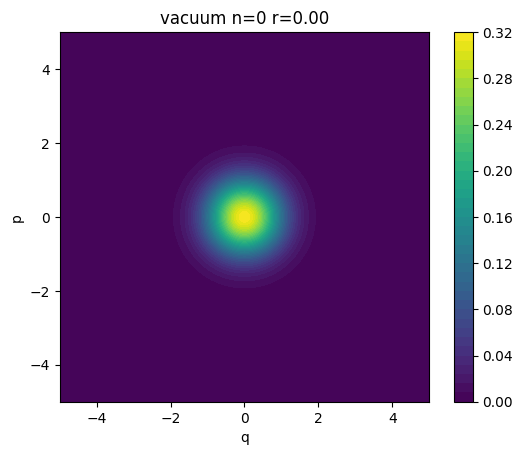

V_q, V_p: 0.25 1.0
W(0,0): 0.3183098861837907


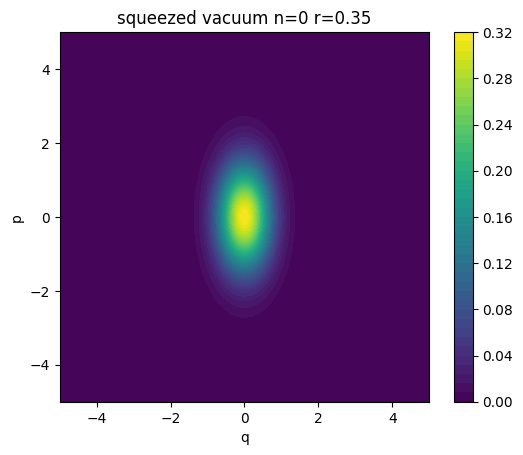

V_q, V_p: 2.5 2.5
W(0,0): 0.06366197723675814


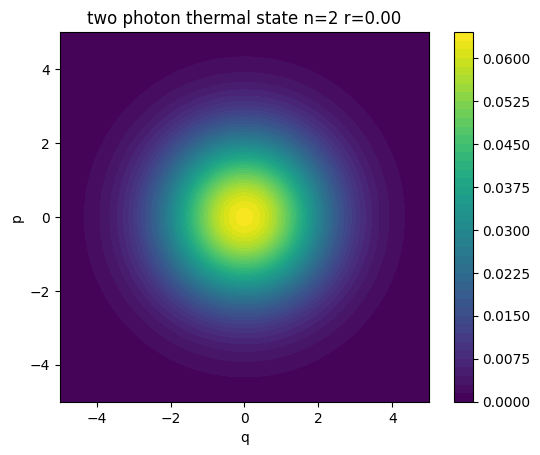

V_q, V_p: 1.25 5.0
W(0,0): 0.06366197723675814


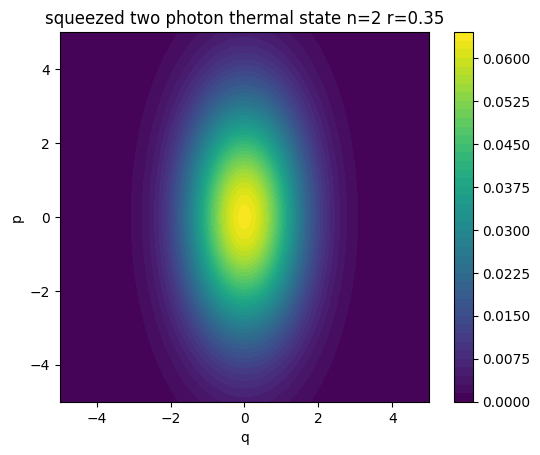

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm

def squeezed(r, n):

  V_q = (2*n+1)*np.exp(-2*r)/2
  V_p = (2*n+1)*np.exp(2*r)/2

  return V_q, V_p

def gauss_wigner(q, p, V_q, V_p):
  denominator = 2*np.pi*np.sqrt(V_q*V_p)
  W = np.exp(-q**2/(2*V_q) - p**2/(2*V_p))/denominator

  return W



#generating phase lattice
x = np.linspace(-5, 5, 401)
y = np.linspace(-5, 5, 401)

q, p = np.meshgrid(x, y, indexing="ij")



cases = [("vacuum", 0, 0), ("squeezed vacuum", 0, np.log(2)/2), ("two photon thermal state", 2, 0), ("squeezed two photon thermal state", 2, np.log(2)/2)]   # a list of tuples
for label, n, r in cases:
  #calculating wigner function for thermal state

  V_q , V_p = squeezed(r, n)
  print("V_q, V_p:", V_q, V_p)
  print("W(0,0):", gauss_wigner(0, 0, V_q, V_p) )

  W = gauss_wigner(q, p, V_q, V_p)



  #plotting phase lattice
  plt.figure()
  plt.title(f'{label} n={n} r={r:.2f}')
  plt.contourf(q, p, W, levels=50); plt.colorbar()
  plt.xlabel("q"); plt.ylabel("p"); plt.gca().set_aspect("equal")
  plt.show()                     # each tuple is unpacked into three names



Wigner Function calculator for one-mode for a pure state. The integral $$W_\phi(q,p):=\frac{1}{\pi}\int dy\;e^{2ip y}\,
  \phi(q-y)\phi^*(q+y),$$ can be approximated by a sum over y

  $$W_\phi(q,p) \approx \frac{dy}{\pi} \sum_i e^{2ip y_i}\,
  \phi(q-y_i)\phi^*(q+y_i)$$
  
For plotting on a grid, we can define a matrix $W_{qy}$ such that

$$W_{qp} = \frac{dy}{\pi} \sum_y G_{qy}E_{yp} \iff W = \frac{dy}{\pi} G E$$

generating the whole grid, where
$$G_{qy} = \phi(q-y)\phi^*(q+y)\quad E_{yp}=e^{2iyp} $$

<>:42: SyntaxWarning: invalid escape sequence '\g'
<>:42: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_2676/1185211613.py:42: SyntaxWarning: invalid escape sequence '\g'
  plt.title(f'Wigner function for $\gamma=${gamma}')


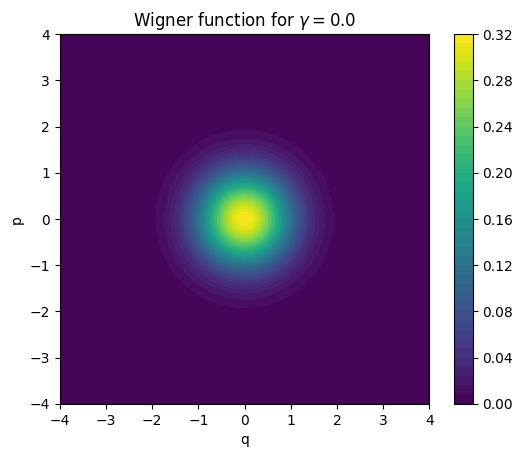

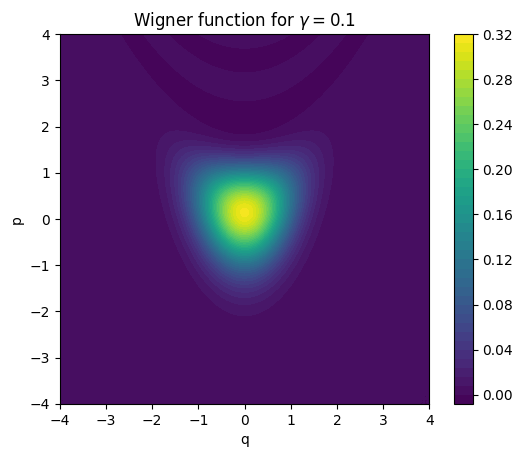

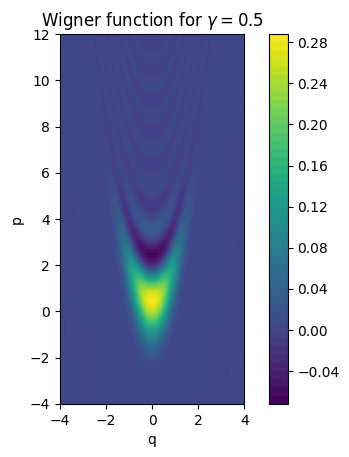

In [ ]:
#calculates the Wigner function for a general one mode state
def Wigner_function(q, p, phi):
  dy = 0.01
  y = np.arange(-10, 10 + dy, dy)
  # matrix E_{yp}
  E = np.exp(2j*np.outer(y, p))
  # matrix G_{qy}
  G = phi(q[ :, None] - y[None, :]) * np.conj(phi(q[:, None] + y[None, :]))
  # matrix \sum_y E_pyG_yq
  integrand = G @ E

  return (dy*integrand/np.pi).real


#generating phase lattice
q = np.linspace(-7, 7, 500)
p = np.linspace(-7, 7, 500)


# the wave function
phi = lambda x: np.pi**-0.25 * np.exp(-x**2 / 2)




cases = [
    {"gamma": 0.0, "q_range": (-4, 4), "p_range": (-4, 4)},
    {"gamma": 0.1, "q_range": (-4, 4), "p_range": (-4, 4)},
    {"gamma": 0.5, "q_range": (-4, 4), "p_range": (-4, 12)},
]
for case in cases:
  gamma = case["gamma"]
  q = np.linspace(*case["q_range"], 500)
  p = np.linspace(*case["p_range"], 500)

  psi = lambda x: phi(x) * np.exp(1j * gamma * x**3)

  W = Wigner_function(q, p, psi)

  #plotting phase lattice
  plt.figure()
  plt.title(f'Wigner function for $\gamma=${gamma}')
  plt.contourf(q, p, W.T, levels=50); plt.colorbar()
  plt.xlabel("q"); plt.ylabel("p"); plt.gca().set_aspect("equal")
  plt.show()                     # each tuple is unpacked into three names

Modelling gaussian noise

It acts as $$W_{\rm out}(q,p)=\frac1T\,\big[W*N_{v/T}\big]\!\left(\frac{q}{\sqrt T},\frac{p}{\sqrt T}\right),$$ for $$
  N_v(x):=\frac{1}{\sqrt{2\pi v}}\,e^{-x^{2}/(2v)},\qquad x\in\mathbb R ^2$$

In [ ]:
from scipy.ndimage import gaussian_filter
# calculates the wigner function for the output state after the initial state suffers gaussian noise
# variance v and transmissivity T
def Wigner_convolution(q, p, psi , v, T):

  dq, dp = q[1] - q[0], p[1] - p[0]

  W_in = Wigner_function(q/np.sqrt(T), p/np.sqrt(T), psi)

  W_out = gaussian_filter(W_in, sigma=(np.sqrt(v)/dq, np.sqrt(v)/dp), mode="constant", truncate=8.0)/T

  return W_out



Here we will compare the wigner function for the input and the output state

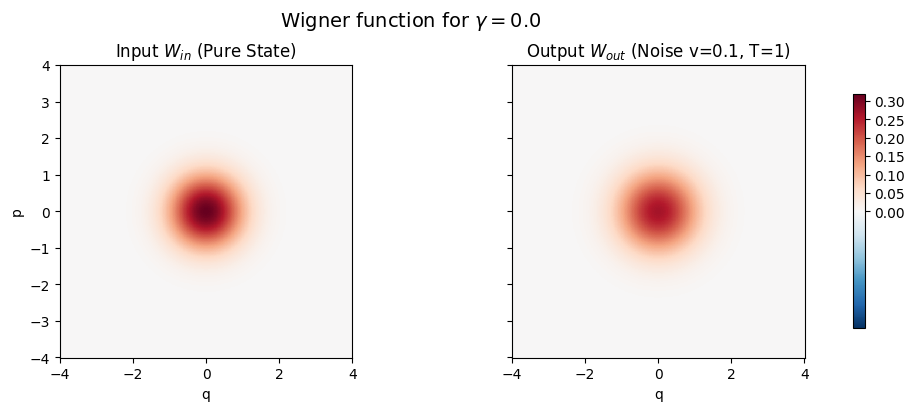

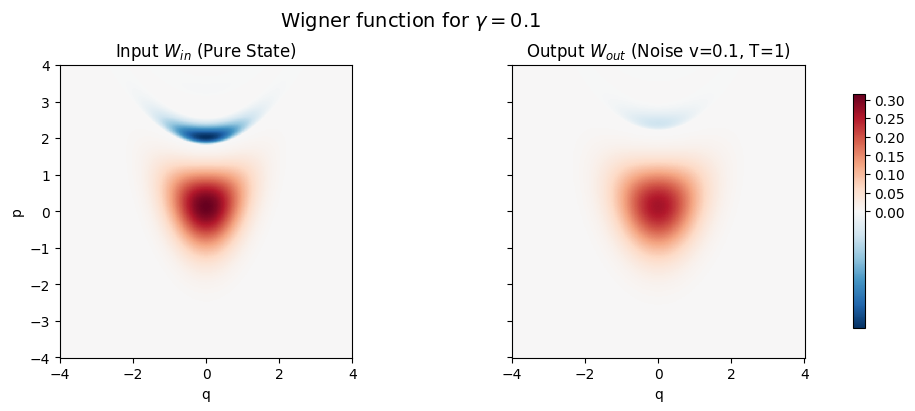

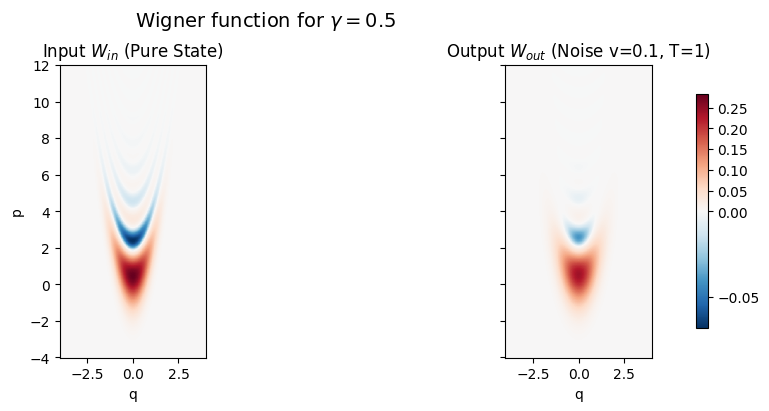

In [15]:
from matplotlib.colors import TwoSlopeNorm


cases_kick = [
    {"gamma": 0.0, "q_range": (-4, 4), "p_range": (-4, 4), "v": 0.1, "T":1},
    {"gamma": 0.1, "q_range": (-4, 4), "p_range": (-4, 4), "v": 0.1, "T":1},
    {"gamma": 0.5, "q_range": (-4, 4), "p_range": (-4, 12), "v": 0.1, "T":1},
]
for case in cases_kick:
  gamma = case["gamma"]
  q = np.linspace(*case["q_range"], 500)
  p = np.linspace(*case["p_range"], 500)

  psi = lambda x: phi(x) * np.exp(1j * gamma * x**3)

  v = case["v"]
  T = case["T"]

  W_out = Wigner_convolution(q, p, psi , v, T)
  W_in = Wigner_function(q, p, psi)

  lo = min(W_out.min(), W_in.min(), -1e-12)      # most negative value of BOTH panels (kept < 0)
  hi = max(W_out.max(), W_in.max())              # largest value of BOTH panels

  norm = TwoSlopeNorm(vmin=lo, vcenter=0.0, vmax=hi)

  #plotting phase lattice side by side
  fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True, constrained_layout=True)
  fig.suptitle(f'Wigner function for $\\gamma={gamma}$', fontsize=14)

  # Plot input Wigner function on the first axis (axes[0])
  im0 = axes[0].pcolormesh(q, p, W_in.T, cmap="RdBu_r", norm=norm, shading="auto")
  axes[0].set_title("Input $W_{in}$ (Pure State)")
  axes[0].set_xlabel("q")
  axes[0].set_ylabel("p")
  axes[0].set_aspect("equal")

  # Plot output Wigner function on the second axis (axes[1])
  im1 = axes[1].pcolormesh(q, p, W_out.T, cmap="RdBu_r", norm=norm, shading="auto")
  axes[1].set_title(f"Output $W_{{out}}$ (Noise v={v}, T={T})")
  axes[1].set_xlabel("q")
  axes[1].set_aspect("equal")

  # Add a single colorbar associated with the normalization
  fig.colorbar(im1, ax=axes, shrink=0.8)
  plt.show()

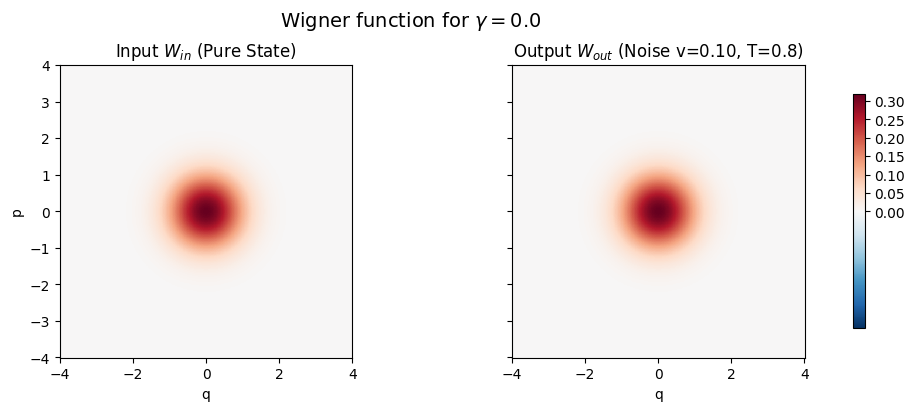

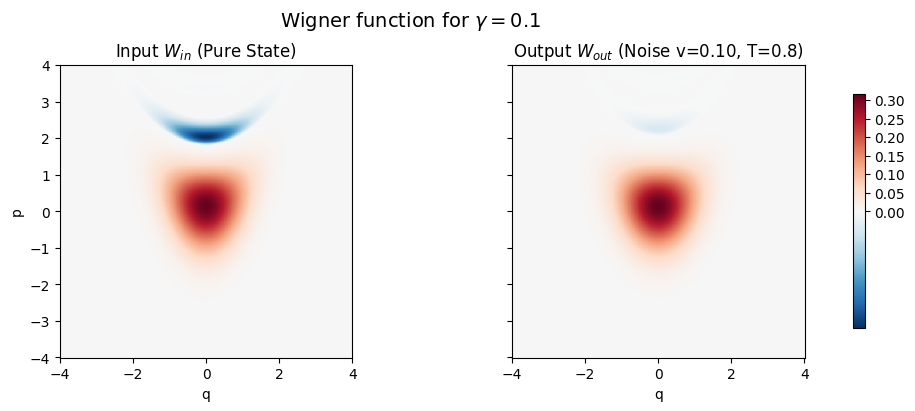

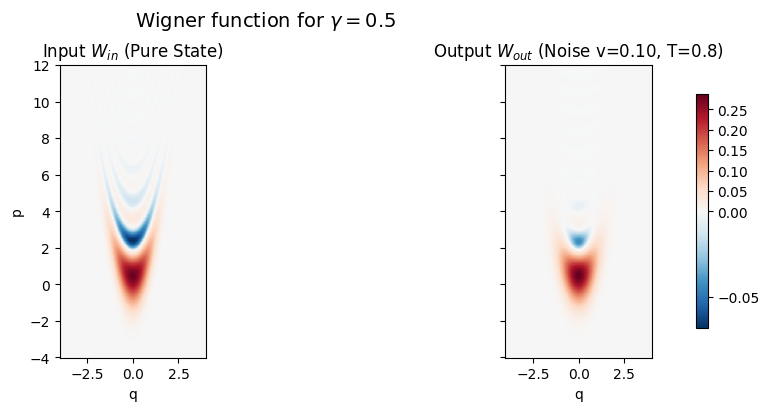

In [19]:
cases_loss = [
    {"gamma": 0.0, "q_range": (-4, 4), "p_range": (-4, 4), "T":0.8 },
    {"gamma": 0.1, "q_range": (-4, 4), "p_range": (-4, 4), "T":0.8 },
    {"gamma": 0.5, "q_range": (-4, 4), "p_range": (-4, 12), "T":0.8 },
]
for case in cases_loss:
  gamma = case["gamma"]
  q = np.linspace(*case["q_range"], 500)
  p = np.linspace(*case["p_range"], 500)

  psi = lambda x: phi(x) * np.exp(1j * gamma * x**3)


  T = case["T"]
  v = (1-T)/2

  W_out = Wigner_convolution(q, p, psi , v, T)
  W_in = Wigner_function(q, p, psi)

  lo = min(W_out.min(), W_in.min(), -1e-12)      # most negative value of BOTH panels (kept < 0)
  hi = max(W_out.max(), W_in.max())              # largest value of BOTH panels

  norm = TwoSlopeNorm(vmin=lo, vcenter=0.0, vmax=hi)

  #plotting phase lattice side by side
  fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True, constrained_layout=True)
  fig.suptitle(f'Wigner function for $\\gamma={gamma}$', fontsize=14)

  # Plot input Wigner function on the first axis (axes[0])
  im0 = axes[0].pcolormesh(q, p, W_in.T, cmap="RdBu_r", norm=norm, shading="auto")
  axes[0].set_title("Input $W_{in}$ (Pure State)")
  axes[0].set_xlabel("q")
  axes[0].set_ylabel("p")
  axes[0].set_aspect("equal")

  # Plot output Wigner function on the second axis (axes[1])
  im1 = axes[1].pcolormesh(q, p, W_out.T, cmap="RdBu_r", norm=norm, shading="auto")
  axes[1].set_title(f"Output $W_{{out}}$ (Noise v={v:.2f}, T={T})")
  axes[1].set_xlabel("q")
  axes[1].set_aspect("equal")

  # Add a single colorbar associated with the normalization
  fig.colorbar(im1, ax=axes, shrink=0.8)
  plt.show()